In [1]:
from src.load_data import load_radioml
X, mods, snrs = load_radioml("../data/RML2016.10a_dict.pkl")
print(X.shape)
print(sorted(set(mods)))
print(sorted(set(snrs)))

(220000, 2, 128)
[np.str_('8PSK'), np.str_('AM-DSB'), np.str_('AM-SSB'), np.str_('BPSK'), np.str_('CPFSK'), np.str_('GFSK'), np.str_('PAM4'), np.str_('QAM16'), np.str_('QAM64'), np.str_('QPSK'), np.str_('WBFM')]
[np.int64(-20), np.int64(-18), np.int64(-16), np.int64(-14), np.int64(-12), np.int64(-10), np.int64(-8), np.int64(-6), np.int64(-4), np.int64(-2), np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18)]


In [2]:
import pandas as pd
df = pd.DataFrame({"mod": mods, "snr": snrs})
print(df["mod"].value_counts())

mod
QPSK      20000
PAM4      20000
AM-DSB    20000
GFSK      20000
QAM64     20000
AM-SSB    20000
8PSK      20000
QAM16     20000
WBFM      20000
CPFSK     20000
BPSK      20000
Name: count, dtype: int64


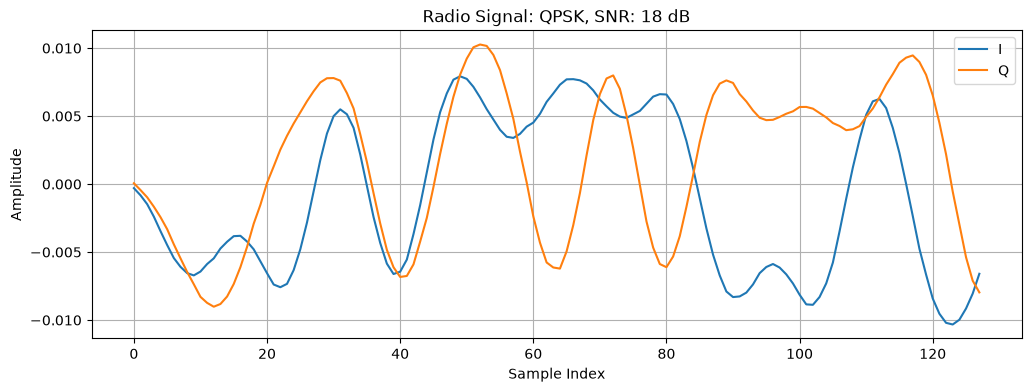

In [3]:
from src.plots import plot_signal

plot_signal(X, mods, snrs, "QPSK", 18)


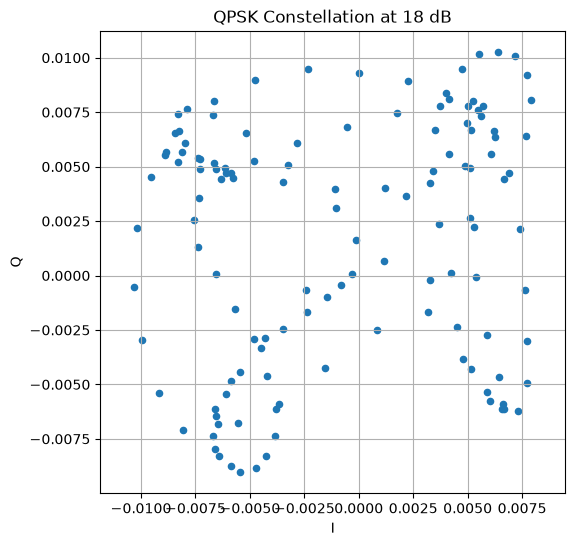

In [4]:
from src.plots import plot_constellation

plot_constellation(X, mods, snrs, "QPSK", 18)

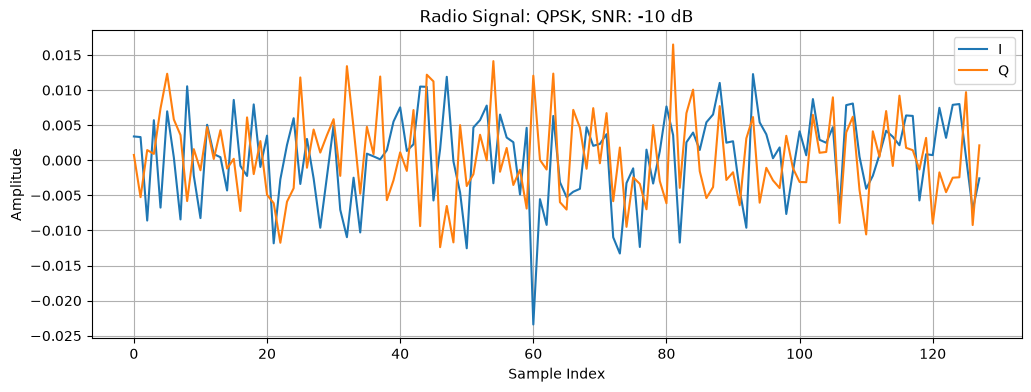

In [5]:
from src.plots import plot_signal

plot_signal(X, mods, snrs, "QPSK", -10)


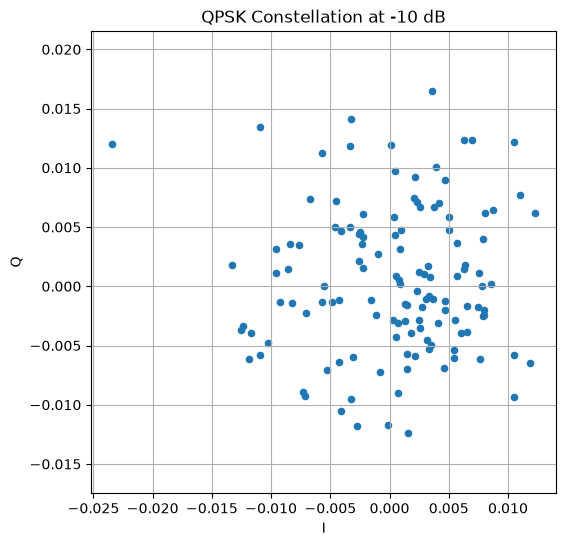

In [6]:
from src.plots import plot_constellation

plot_constellation(X, mods, snrs, "QPSK", -10)

After comparing 2 signals that are the same modulation but differ in SNR. The constellation graph for QPSK at 18 dB shows the points sweep in arcs between four corner regions. While compared to the constellation graph of QPSK at -10 dB hte plots are just noise and show a blob with no structure.

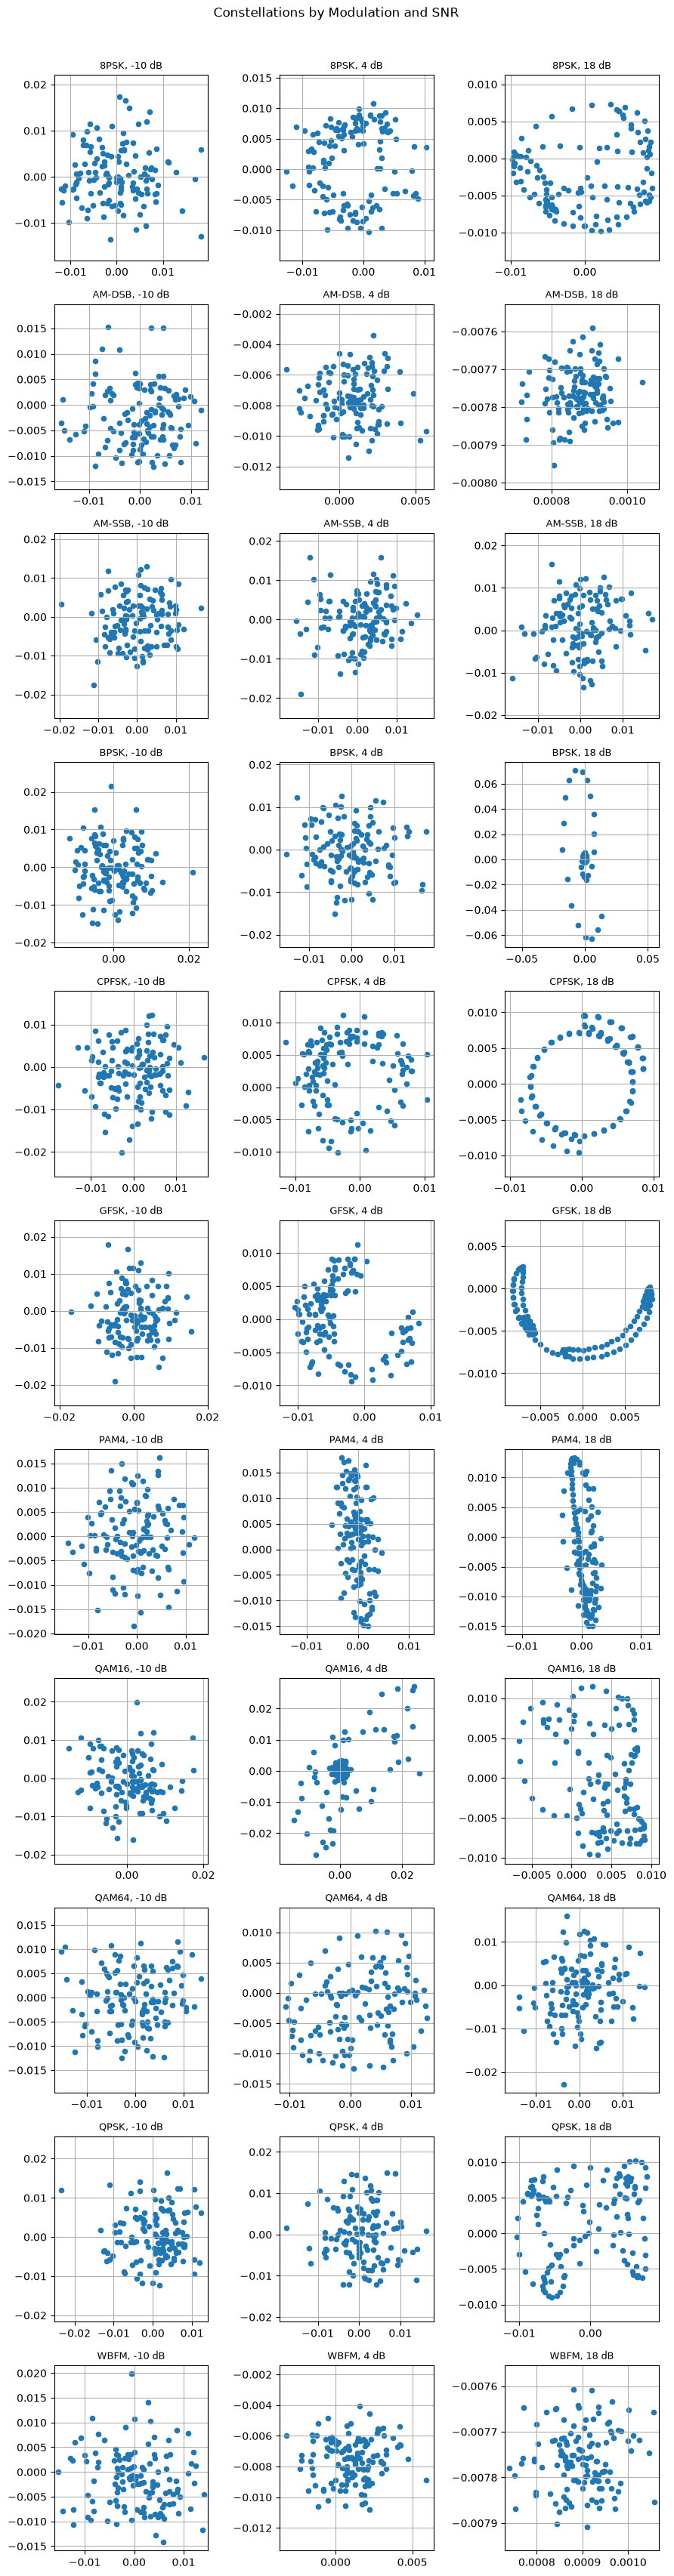

In [7]:
import numpy as np
import matplotlib.pyplot as plt

mod_list = sorted(set(mods))
snr_list = [-10, 4, 18]

fig, axes = plt.subplots(len(mod_list), len(snr_list), figsize=(9, 34))

for row, mod in enumerate(mod_list):
    for col, snr in enumerate(snr_list):
        indices = np.where((mods == mod) & (snrs == snr))[0]
        signal = X[indices[0]]

        I = signal[0]
        Q = signal[1]

        ax = axes[row, col]
        ax.scatter(I, Q, s=20)
        ax.set_title(f"{mod}, {snr} dB", fontsize=9)
        ax.grid(True)
        ax.axis("equal")

fig.suptitle("Constellations by Modulation and SNR", y=1.002)
fig.tight_layout(rect=[0, 0, 1, 0.995])
fig.savefig("../figures/constellations.png")
plt.show()


From the grid you can now see that for every modulation that at -10 dB the graphs form a blob with zero structure. While the grpahs for the modulation that are at 18 dB now tighten up and form shapes. For example the CPFSK forms a ring while BPSK forms a vertical line. As the SNR increases the graphs start to take shape.